In [1]:
import warnings
warnings.filterwarnings(action='ignore')

시각화를 하기 위해서 matplotlib, seaborn를 설치하고 import 한다.  
`!pip install matplotlib seaborn`  

matplotlib은 파이썬에서 가장 널리 쓰이는 기본적이고 강력한 저수준(Low-level) 시각화 라이브러리이고 seaborn은 matplotlib을 기반으로 만들어진 통계 데이터 시각화 전용 고수준(High-level) 라이브러리이다.

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib 라이브러리 사용시 한글이 깨지는 현상을 방지하기 위해서 koreanize_matplotlib 라이브러리를 설치하고 import 한다.  
`!pip install koreanize_matplotlib`

koreanize_matplotlib 라이브러리를 설치하고 import 하면 별도의 설정없이 한글이 안깨진다.

In [67]:
import koreanize_matplotlib

# 앤스콤 4분할 그래프

사람의 눈은 수백 줄의 텍스트만으로 이루어진 데이터를 읽거나 기초 통계 수치를 계산하는 방법으로는 데이터를 제대로 분석할 수 없기 때문에 데이터 전처리 과정에서 데이터의 숨겨진 패턴을 파악하기 위해 데이터 시각화를 사용한다.

앤스콤 4분할 그래프는 데이터를 시각화하지 않고 수치만 확인했을 때 발생될 수 있는 함정을 보여주는 그래프이다.  
엔스콤 데이터셋은 4개의 그룹으로 구성되어 있으며 4개의 데이터 그룹은 각각 평균, 분산 같은 수치나 상관관계 회귀선이 모두 같다는 특징이 있다. 그래서 이런 결과를 보면 4개의 데이터셋 데이터는 모두 같을것이라고 착각할 수 있다.

앤스콤 데이터셋은 seaborn 라이브러리가 제공하고 load_dataset() 메소드를 이용해서 불러올 수 있다.

In [68]:
anscombe_df = sns.load_dataset('anscombe')
anscombe_df

,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33
5,I,14.0,9.96
6,I,6.0,7.24
7,I,4.0,4.26
8,I,12.0,10.84
9,I,7.0,4.82


In [69]:
subset1 = anscombe_df[anscombe_df['dataset'] == 'I'].drop('dataset', axis=1)
subset1.mean()

x    9.000000
y    7.500909
dtype: float64

In [70]:
subset2 = anscombe_df[anscombe_df['dataset'] == 'II'].drop('dataset', axis=1)
subset2.mean()

x    9.000000
y    7.500909
dtype: float64

In [71]:
subset3 = anscombe_df[anscombe_df['dataset'] == 'III'].drop('dataset', axis=1)
subset3.mean()

x    9.0
y    7.5
dtype: float64

In [72]:
subset4 = anscombe_df[anscombe_df['dataset'] == 'IV'].drop('dataset', axis=1)
subset4.mean()

x    9.000000
y    7.500909
dtype: float64

In [73]:
anscombe_df.groupby('dataset').describe()

x                                               y            \
        count mean       std  min  25%  50%   75%   max count      mean   
dataset                                                                   
I        11.0  9.0  3.316625  4.0  6.5  9.0  11.5  14.0  11.0  7.500909   
II       11.0  9.0  3.316625  4.0  6.5  9.0  11.5  14.0  11.0  7.500909   
III      11.0  9.0  3.316625  4.0  6.5  9.0  11.5  14.0  11.0  7.500000   
IV       11.0  9.0  3.316625  8.0  8.0  8.0   8.0  19.0  11.0  7.500909   

                                                   
              std   min    25%   50%   75%    max  
dataset                                            
I        2.031568  4.26  6.315  7.58  8.57  10.84  
II       2.031657  3.10  6.695  8.14  8.95   9.26  
III      2.030424  5.39  6.250  7.11  7.98  12.74  
IV       2.030579  5.25  6.170  7.04  8.19  12.50

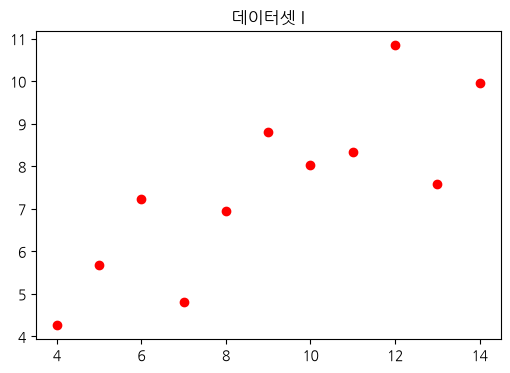

In [74]:
# figure() 메소드의 figsize를 이용해서 전체 그래프가 그려질 기본 틀을 만든다.
plt.figure(figsize=[6, 4])
plt.plot(subset1['x'], subset1['y'], 'ro')
# title() 메소드로 그래프에 제목을 넣을 수 있다.
plt.title('데이터셋 I')
plt.show()

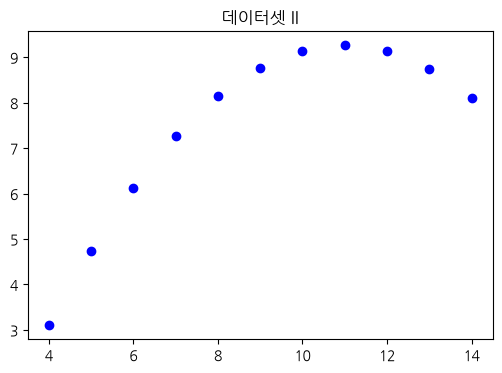

In [75]:
plt.figure(figsize=[6, 4])
plt.plot(subset2['x'], subset2['y'], 'bo')
plt.title('데이터셋 II')
plt.show()

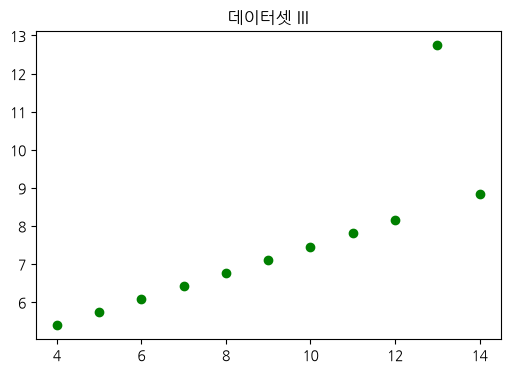

In [76]:
plt.figure(figsize=[6, 4])
plt.plot(subset3['x'], subset3['y'], 'go')
plt.title('데이터셋 III')
plt.show()

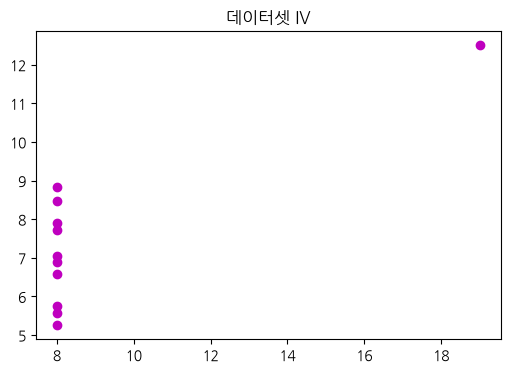

In [77]:
plt.figure(figsize=[6, 4])
plt.plot(subset4['x'], subset4['y'], 'mo')
plt.title('데이터셋 IV')
plt.show()

## subplot

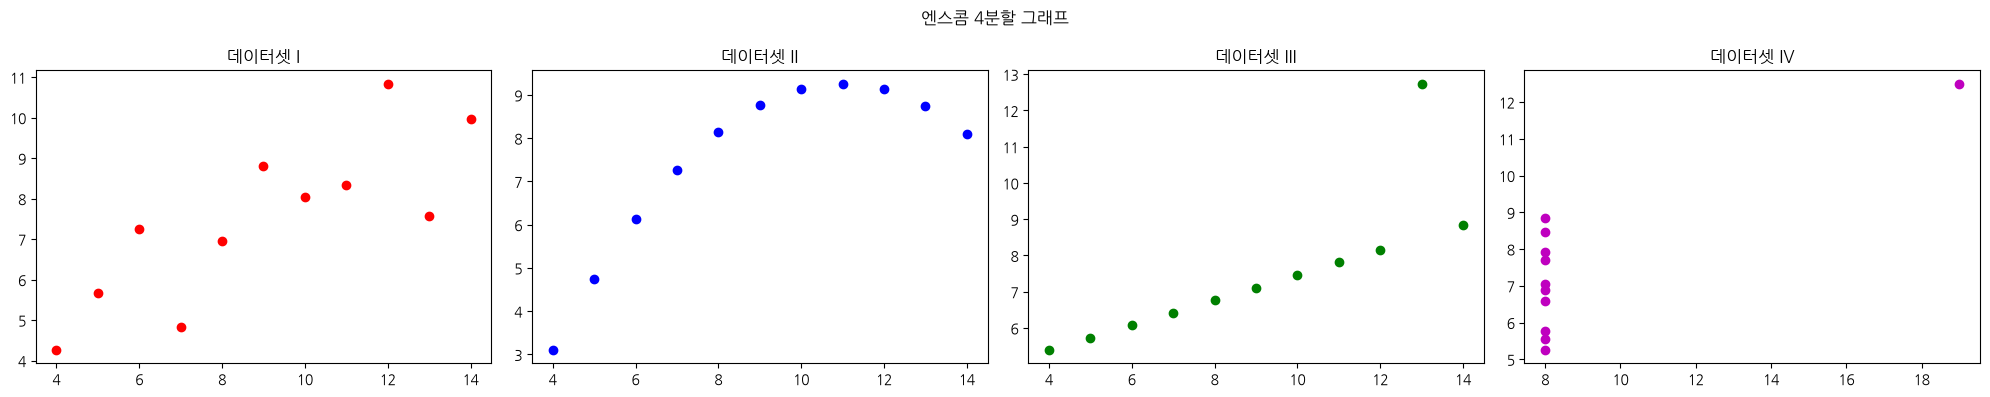

In [80]:
fig = plt.figure(figsize=[20, 4])
# add_subplot() 메소드로 그래프의 격자를 만들고 각각의 격자에 들어갈 그래프 출력위치를 지정한다.
# add_subplot(격자의 행 개수, 격자의 열 개수, 격자 내부에서 그래프를 출력할 위치)
axes1 = fig.add_subplot(1, 4, 1)
axes2 = fig.add_subplot(1, 4, 2)
axes3 = fig.add_subplot(1, 4, 3)
axes4 = fig.add_subplot(1, 4, 4)
# plot() 메소드로 각 격자에 그래프를 그린다.
axes1.plot(subset1['x'], subset1['y'], 'ro')
axes2.plot(subset2['x'], subset2['y'], 'bo')
axes3.plot(subset3['x'], subset3['y'], 'go')
axes4.plot(subset4['x'], subset4['y'], 'mo')
# suptitle() 메소드로 그래프 전체의 제목을 넣을 수 있다.
fig.suptitle('엔스콤 4분할 그래프')
# set_title() 메소드로 subplot 그래프의 제목을 넣을 수 있다.
axes1.set_title('데이터셋 I')
axes2.set_title('데이터셋 II')
axes3.set_title('데이터셋 III')
axes4.set_title('데이터셋 IV')
# 그래프의 제목이 너무 가깝거나 겹쳐보일 때 tight_layout() 메소드를 실행하면 그래프의 레이아웃이 겹치지 않도록 자동으로 조정한다.
fig.tight_layout()
plt.show()